# Notebook 13: Indivisibility vs Wigner Negativity

**Goal:** Notebook 03 found that the "derived intermediate" of a quantum process has negative entries. Phase-space quantum mechanics has its own famous
negativity: the Wigner function. Are they the same thing?

By the end of this notebook you will be able to:
- Build the discrete Wigner function on a $5\times5$ phase space and check that summing over "momentum" gives the configuration probabilities
- Show that every unitary moves the Wigner function by a matrix that composes exactly (a signed Markov chain), and that Γ is that chain with the
  momentum forgotten: $\Gamma = \Pi\,M\,E$
- Show that the two negativities come apart: a Clifford gate moves phase space by a pure permutation, yet the two-step process $F\cdot F$ is indivisible
  (no stochastic intermediate exists at all); a cubic phase gate needs negative weights, yet its Γ is divisible
- Measure both over random circuits: which form the indivisibility takes when there is no Wigner negativity, and whether the two sizes are correlated

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Study copy of `13_wigner.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-10-24 from the Wigner spike (`notes/wigner-spike-2026-10-24.md`), item 3 of the textbook backlog
> (`notes/textbook-concepts-backlog-2026-10-24.md`), prompted by Schleich's *Quantum Optics in Phase Space* §3.3.2. The question: *is the negativity
> notebook 03 found in Γ's derived intermediates the same as the negativity of the Wigner function?* Short answer: no. Each can occur without the
> other, but not symmetrically: without Wigner negativity, the indivisibility seen here is always of the "no stochastic intermediate at all" kind, never notebook 03's
> negative derived intermediate. Γ is the momentum-forgetting marginal of an exactly composing (signed) phase-space process.
>
> **Prior work.** $\Gamma = \Pi M E$ is the marginal of a quasi-probability simulation, as in Pashayan, Wallman and Bartlett (2015), eq. 3, building on Veitch et al. (2012)
> and Mari and Eisert (2012). Reading indivisibility as a forgotten coordinate is close to Barandes's own picture (Paper 3, §2.1, in its Newtonian form; arXiv:2602.01043, "Markovian embeddings"). That the two negativities come apart is known in substance from that work; the notebook restates it in Γ language (see the 🔭 cell at the end).
>
> Right after this banner: a summary of what Γ explains here and what it doesn't.
---

### 📖 In depth: what Γ explains about phase space, and what it doesn't

**What Γ explains**
- **Where indivisibility can come from.** Forgetting a hidden coordinate (section 2). Even a perfectly classical hidden motion produces an indivisible Γ (section 3).
- **What a division event does in phase space.** It forgets the momentum and restarts it uniformly (section 2).
- **That indivisibility and Wigner negativity measure different things** (sections 3–5).

**What Γ does not explain**
- **Which hidden coordinate.** The Wigner function is one unfolding of Γ, built from Hilbert-space operators (phase-point operators). Γ alone does not pick it out.
- **Classical simulability.** Whether a circuit can be simulated efficiently is tied to Wigner negativity (Veitch et al. 2012; Mari and Eisert 2012), which Γ does not see: the cubic
  phase gate has a trivial Γ.
- **Why the Clifford gates are special.** Their permutation action comes from the symplectic structure of phase space, not from Γ.

**Net.** Γ's indivisibility is a statement about what is forgotten; Wigner negativity is a statement about what cannot be unfolded positively. A process can have either
without the other, although without Wigner negativity only the singular kind of indivisibility appeared here (section 5).

<!-- expansion:13:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Notebook 03 showed that a quantum process cannot be split at an intermediate time: the "middle leg" would need negative probabilities.
Quantum optics has another famous negative quantity, the Wigner function, often described as the signature of genuinely quantum behaviour. It is natural to guess
these are the same thing. This notebook tests that guess on a small discrete phase space, and finds they are not the same, though they are not fully
independent either.

**Prerequisites.**
- Notebook 03: indivisibility and the derived intermediate.
- Notebook 05: the linear-program test for whether *any* stochastic intermediate exists (used here as the "defect").
- Notebook 06: division events.
- Notebook 12: imaginary time as another way to trade indivisibility for a Markov chain.
- No prior knowledge of Wigner functions; the 📘 and 📚 cells cover what is needed.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*. The first code cell imports from `isp/wigner.py`, so `isp/` must sit next to `notebooks/`.
Needs numpy, scipy and matplotlib. It runs in about ten seconds; section 5 is the slowest (900 pairs of circuits).

**Search-engineer framing.** If you log only which page a user is on, their behaviour can look history-dependent. Log also where they were heading and it may become
memoryless. This notebook is that observation, with "page" = configuration and "heading" = momentum.


<!-- expansion:13:glossary -->
### 📘 Glossary

- **Configuration $q$.** One of $d = 5$ definite states (the computational basis).
- **Momentum $p$.** The second phase-space coordinate; not a configuration, and not recorded by Γ.
- **Phase space.** The $d\times d$ grid of pairs $(q, p)$.
- **Wigner function $W(q, p)$.** A real function on phase space that represents a state: it sums to 1, its sums over $p$ are the configuration probabilities, and it can be negative.
- **Phase-point operators $A(q, p)$.** The 25 matrices that define $W$ via $W(q,p) = \mathrm{Tr}(\rho A(q,p))/d$.
- **Wigner map $M(U)$.** The $25\times25$ matrix that moves $W$ under a unitary $U$. Columns sum to 1; can have negative entries.
- **Lift $E$ and marginal $\Pi$.** $E$ spreads a configuration uniformly over momentum; $\Pi$ sums over momentum. $\Gamma = \Pi M E$.
- **Clifford gates.** Fourier $F$, shear (quadratic phase) $S$, shifts $X$, $Z$: the discrete analogue of motion in at most quadratic potentials. In odd $d$ their Wigner maps are permutations.
- **Cubic phase gate $C$.** $\mathrm{diag}(\omega^{q^3})$; not Clifford for $d \ge 5$; its Wigner map has negative entries.
- **Negative mass.** The largest total negative weight in a column of a matrix.
- **Indivisibility defect.** The smallest $\|D\,\Gamma_1 - \Gamma_{12}\|_1$ over stochastic $D$, found by linear programming; zero exactly when a stochastic intermediate exists. At most $2(d-1) = 8$.
- **Haar-random unitary.** A unitary drawn uniformly at random.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.stats import unitary_group, spearmanr
from isp.wigner import DiscretePhaseSpace, negative_mass, is_permutation, indivisibility_defect

### 📖 In depth: two kinds of negativity, in plain words

- **Notebook 03's negativity.** Γ tells you where a system starting in configuration $j$ is likely to be at time $t$. If you try to split the journey at an intermediate time,
  the "middle leg" you would need has negative entries. That is indivisibility.
- **Wigner negativity.** Phase-space quantum mechanics describes a state by a function on (configuration, momentum) pairs. For some states that function goes negative,
  so it cannot be a probability distribution.
- **The question.** Both are "negative probabilities appearing where classical physics expects positive ones". Are they two faces of one thing?
- **The answer here.** Not the same, though not fully independent either. A process can move phase space around as a pure, classical shuffle and still be indivisible,
  because Γ forgets the momentum, and the momentum carries the memory. In that case, though, the first step's Γ cannot be inverted, so there is no "middle leg" at all
  rather than a negative one; notebook 03's negative middle leg showed up here only together with Wigner negativity. And a process can need negative phase-space
  weights while Γ does nothing at all.
- **For a search engineer.** Session behaviour that looks history-dependent when you log only the page (configuration) can be perfectly memoryless once you also log a hidden
  state (momentum: where the user was heading). Indivisibility in the page log says nothing about whether that hidden state is "exotic".

## 1. A Discrete Phase Space

Take $d = 5$ configurations $q = 0,\dots,4$. The discrete Wigner function (Wootters; Gross) adds a second coordinate, a "momentum" $p = 0,\dots,4$, and assigns each state a
function $W(q, p)$ on the $5\times5$ grid. It sums to 1, and **summing over $p$ gives the probability of each configuration**. Unlike a probability distribution, $W$ can be negative.

A configuration itself, $|q_0\rangle$, has $W = 1/5$ along the line $q = q_0$: non-negative, and uniform in momentum.

<!-- expansion:13:books-schleich -->
### 📚 From the books: Schleich on phase space, Barandes on what Γ forgets

- **Schleich**, *Quantum Optics in Phase Space*, §3.3.2 "Quantum Liouville Equation" (printed p. 76). For a potential with terms only up to second order in position,
  "each point in Wigner function phase space moves according to the classical equations of motion. The quantum mechanical properties of a system are then hidden in
  the initial condition. Whereas in classical mechanics any normalizable, non-negative distribution function is allowed, this is no longer true in quantum mechanics."
- **Schleich**, §3.2.3 "Shape of Wigner Function" (printed p. 73), under the heading "Wigner Functions Can Take on Negative Values": the property usually treated as the mark of the quantum.
- **Barandes**, *Correspondence* §3.4: $\Gamma_{ij} = |U_{ij}|^2$ keeps only configuration probabilities at each time; the phases of $U$, which the Wigner function records
  through the momentum, are not in any single Γ. They still matter across times: relative phases have "clear empirical signatures" (§3.6).

The discrete version used here is due to Wootters (1987) and Gross (2006).


configuration $|2\rangle$   : sum of W = 1.000,  smallest entry = +0.000,  marginal over p matches ⟨q|ρ|q⟩: True
a "cubic" state             : sum of W = 1.000,  smallest entry = -0.089,  marginal over p matches ⟨q|ρ|q⟩: True


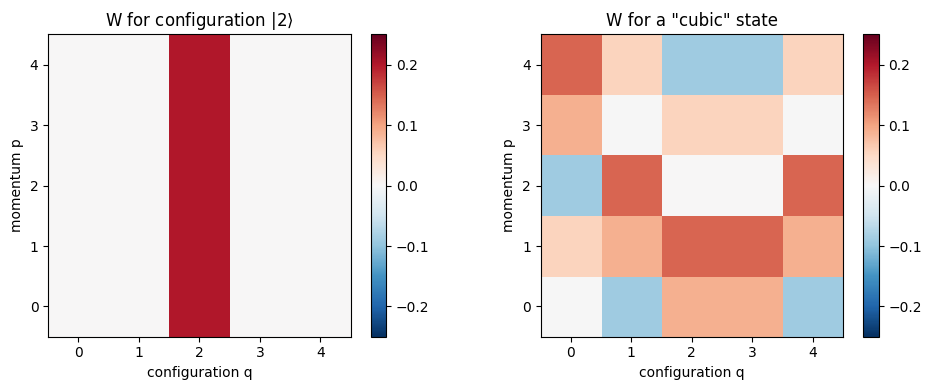

In [2]:
ps = DiscretePhaseSpace(5)
d = ps.d

rho_conf = np.zeros((d, d)); rho_conf[2, 2] = 1
psi = ps.cubic() @ ps.fourier()[:, 0]                  # cubic phase applied to the uniform superposition
rho_cubic = np.outer(psi, psi.conj())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, rho, title in [(ax[0], rho_conf, 'configuration $|2\\rangle$'), (ax[1], rho_cubic, 'a "cubic" state')]:
    W = ps.wigner(rho)
    im = a.imshow(W.T, origin='lower', cmap='RdBu_r', vmin=-0.25, vmax=0.25)
    a.set_xlabel('configuration q'); a.set_ylabel('momentum p'); a.set_title(f'W for {title}')
    plt.colorbar(im, ax=a, fraction=0.046)
    print(f"{title:28s}: sum of W = {W.sum():.3f},  smallest entry = {W.min():+.3f},"
          f"  marginal over p matches ⟨q|ρ|q⟩: {np.allclose(W.sum(axis=1), np.diag(rho).real)}")
plt.tight_layout(); plt.show()

### 🔍 Reading the code

- **`DiscretePhaseSpace(5)`** builds the 25 phase-point operators $A(q, p)$. $W(q, p) = \mathrm{Tr}(\rho A(q, p))/d$.
- **`ps.cubic() @ ps.fourier()[:, 0]`**: the first column of the Fourier matrix is the uniform superposition $\frac{1}{\sqrt5}\sum_q|q\rangle$; the cubic phase then gives it a
  non-quadratic phase. This is a standard example of a state with a negative Wigner function.
- **The plot** shows $W$ with configuration $q$ across and momentum $p$ up. Red is positive, blue negative. The configuration $|2\rangle$ is a vertical stripe at $q = 2$.
- **The printout** checks that $W$ sums to 1 and that summing each column over $p$ gives the configuration probabilities.

<!-- expansion:13:recap-1 -->
### 📝 Recap: section 1

- The discrete Wigner function lives on a $5\times5$ grid of (configuration, momentum) pairs; it sums to 1 and its momentum sums are the configuration probabilities.
- A configuration is a uniform stripe in momentum: non-negative.
- Other states, like the "cubic" one, have negative entries.


## 2. Dynamics on Phase Space, and Γ as Its Marginal

A unitary $U$ moves the Wigner function linearly: $W \mapsto M(U)\,W$, with $M$ a $25\times25$ matrix. Two facts make $M$ look like a Markov chain on phase space: its columns sum to 1,
and it composes exactly, $M(U_2U_1) = M(U_2)M(U_1)$. The one difference from a Markov chain is that $M$ can have negative entries, and therefore entries greater than 1.

Γ lives on configurations only. Start in configuration $q_0$ (uniform in momentum), move with $M$, then forget the momentum:

$$\Gamma(U) = \Pi\,M(U)\,E, \qquad E = \text{spread a configuration uniformly over } p, \quad \Pi = \text{sum over } p .$$

<!-- expansion:13:derive-gamma -->
### 🧮 Worked derivation: Γ = Π M E, entry by entry

Start in configuration $j$. Its Wigner function is $W_0(q, p) = \delta_{qj}/d$, i.e. column $j$ of $E$. After $U$, $W_1 = M(U)W_0$. The probability of configuration $i$ is
$\sum_p W_1(i, p)$, which is row $i$ of $\Pi$ applied to $W_1$. So

$$\Gamma_{ij} = \sum_p \sum_{p'} M_{(i,p),(j,p')}\,\frac{1}{d} = (\Pi M E)_{ij}.$$

Two steps: $\Gamma(U_2U_1) = \Pi M_2 M_1 E$. Insert a division event after the first step: $\Pi M_2 (E\Pi) M_1 E = (\Pi M_2 E)(\Pi M_1 E) = \Gamma(U_2)\Gamma(U_1)$.
**So the two-step Γ equals $\Gamma(U_2)\Gamma(U_1)$ exactly when $M_1E$ can be replaced by $E\Pi M_1E$ without changing what $\Pi M_2$ sees**, i.e. when the momentum after the first step
carries nothing the second step will turn into configuration. (Divisibility in general allows any stochastic intermediate, not only $\Gamma(U_2)$, so it is a weaker condition.)


In [3]:
rng = np.random.default_rng(1)
U1, U2 = unitary_group.rvs(d, random_state=rng), unitary_group.rvs(d, random_state=rng)
M1, M2, M12 = ps.wigner_map(U1), ps.wigner_map(U2), ps.wigner_map(U2 @ U1)
G1, G12 = np.abs(U1) ** 2, np.abs(U2 @ U1) ** 2

print(f"columns of M sum to 1:          {np.allclose(M1.sum(axis=0), 1)}")
print(f"M(U2 U1) = M(U2) M(U1):          {np.allclose(M12, M2 @ M1)}   (phase space: always composes, with signed weights)")
print(f"negative mass of M(U1):          {negative_mass(M1):.3f}")
print(f"Γ(U1) = Π M(U1) E:               {np.allclose(ps.marginal @ M1 @ ps.lift, G1)}")
print(f"configurations: defect of the two-step Γ = {indivisibility_defect(G1, G12):.3f}   (> 0: indivisible)")

EP = ps.lift @ ps.marginal          # forget the momentum, then spread uniformly again: a division event
print(f"\nwith a division event between the steps, Π M2 (EΠ) M1 E = Γ(U2) Γ(U1): "
      f"{np.allclose(ps.marginal @ M2 @ EP @ M1 @ ps.lift, np.abs(U2) ** 2 @ G1)}")

columns of M sum to 1:          True
M(U2 U1) = M(U2) M(U1):          True   (phase space: always composes, with signed weights)
negative mass of M(U1):          1.656
Γ(U1) = Π M(U1) E:               True
configurations: defect of the two-step Γ = 1.258   (> 0: indivisible)

with a division event between the steps, Π M2 (EΠ) M1 E = Γ(U2) Γ(U1): True


### 📖 In depth: why Γ is the marginal of the Wigner map

The phase-point operators form a basis with $\mathrm{Tr}(A_aA_b) = d\,\delta_{ab}$, so any operator can be expanded in them, and conjugating by $U$ just re-expands: that is the matrix $M(U)$.
Because $U_2U_1$ conjugates in two steps, $M(U_2U_1) = M(U_2)M(U_1)$ exactly. Because $\sum_a A_a = d\,I$, the trace is preserved, so columns sum to 1.

For Γ: start in $|j\rangle$, whose Wigner function is $E e_j$ (uniform in momentum on the line $q = j$). Move it with $M$. The probability of configuration $i$ is the sum of the new $W$ over
momentum on the line $q = i$: $\Pi$. So $\Gamma_{ij} = (\Pi M E)_{ij}$.

A division event records the configuration and destroys the coherence between configurations. A diagonal density matrix has a Wigner function that is uniform in momentum,
so recording is $E\Pi$: keep the configuration probabilities, forget the momentum. That is why division events make Γ compose.

<!-- expansion:13:recap-2 -->
### 📝 Recap: section 2

- On phase space, every unitary acts by a matrix that composes exactly: a Markov chain, except that some weights may be negative.
- Γ is that chain with the momentum forgotten: $\Gamma = \Pi M E$.
- A division event is $E\Pi$, "forget the momentum and start it uniform"; with it, Γ composes.


## 3. Classical Phase-Space Dynamics, Indivisible Γ

The **Clifford** gates (the discrete Fourier transform $F$, the quadratic phase or "shear" $S$, shifts) are the discrete analogue of motion in a potential that is at most quadratic.
Schleich's *Quantum Optics in Phase Space* (§3.3.2) says that there "each point in Wigner function phase space moves according to the classical equations of motion".
Check that for $F$, then ask what Γ does.

<!-- expansion:13:howto-3 -->
### 🧭 How to read the next cell

- **First block:** each Clifford gate's Wigner map is checked for being a permutation (every column a single 1).
- **Second line:** where $F$ sends five phase-space points. Read $(1, 0) \to (0, 1)$ as "configuration 1 with momentum 0 goes to configuration 0 with momentum 1".
- **The two matrices:** $\Gamma(F)$, uniform, and $\Gamma(F^2)$, the permutation $q \to -q$ (mod 5).
- **The defect:** any stochastic $D$ turns the uniform $\Gamma(F)$ into a matrix whose columns are all the same distribution $v$. Against the permutation $\Gamma(F^2)$ the residual is
  $\sum_j 2\,(1 - v_{\sigma(j)}) = 2(d - 1) = 8$, whatever $v$ is. So 8 is exact: no choice of intermediate does any better than any other.
- **Things to try:** replace `F` by `S` in the last four lines; the shear moves no configuration, so its Γ is the identity and the defect is 0.


In [4]:
F, S = ps.fourier(), ps.shear()
for name, U in [("Fourier F", F), ("shear S", S), ("F S", F @ S)]:
    M = ps.wigner_map(U)
    print(f"{name:10s}: M is a permutation of the 25 phase-space points: {is_permutation(M)}")

MF = ps.wigner_map(F)
moves = {ps.points[b]: ps.points[int(np.argmax(MF[:, b]))] for b in range(d * d)}
print("\nwhere F sends a few points (q, p):", {k: moves[k] for k in [(0, 0), (1, 0), (2, 0), (0, 1), (1, 1)]})

GF, GFF = np.abs(F) ** 2, np.abs(F @ F) ** 2
print("\nΓ(F) (every entry 1/5):\n", np.round(GF, 3))
print("Γ(F F) (a permutation: q → −q):\n", np.round(GFF, 3))
print(f"\nΓ(F F) = Γ(F) Γ(F): {np.allclose(GFF, GF @ GF)}")
print(f"defect (smallest ‖D Γ(F) − Γ(FF)‖₁ over stochastic D): {indivisibility_defect(GF, GFF):.3f}")

Fourier F : M is a permutation of the 25 phase-space points: True
shear S   : M is a permutation of the 25 phase-space points: True
F S       : M is a permutation of the 25 phase-space points: True

where F sends a few points (q, p): {(0, 0): (0, 0), (1, 0): (0, 1), (2, 0): (0, 2), (0, 1): (4, 0), (1, 1): (4, 1)}

Γ(F) (every entry 1/5):
 [[0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]
 [0.2 0.2 0.2 0.2 0.2]]
Γ(F F) (a permutation: q → −q):
 [[1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0.]]

Γ(F F) = Γ(F) Γ(F): False
defect (smallest ‖D Γ(F) − Γ(FF)‖₁ over stochastic D): 8.000


### 📖 In depth: why a classical shuffle gives an indivisible Γ

$F$ rotates phase space by a quarter turn: a point $(q, p)$ goes to $(-p, q)$ (the printout). Start in configuration $q_0$: a vertical line, uniform in $p$. After $F$ it is a horizontal line,
spread uniformly over every configuration, so $\Gamma(F)$ has every entry $1/5$. After $F$ again it is a vertical line at $-q_0$: $\Gamma(F^2)$ is the permutation $q \to -q$.

The configuration log after one step shows a uniform spread and has forgotten $q_0$. But phase space has not forgotten: the information moved into the momentum, and the second
step moves it back. Any process that only uses the configuration at the middle time must map "uniform" to the same distribution whatever $q_0$ was, so it cannot reproduce the
permutation. Hence no stochastic intermediate, and the defect printed above. Since $\Gamma(F)$ is singular, notebook 03's derived intermediate
$\Gamma(F^2)\Gamma(F)^{-1}$ does not exist: this is indivisibility of the "no intermediate at all" kind, not a middle leg with negative entries.

Nothing here is quantum in the sense of negativity: every phase-space point moves deterministically. Schleich's statement that quadratic dynamics is classical in phase space is
exactly right; Γ is indivisible anyway, because it discards the momentum.

<!-- expansion:13:recap-3 -->
### 📝 Recap: section 3

- Clifford gates move phase space by permutations: classical, deterministic, no negativity (Schleich's "classical equations of motion").
- Yet $\Gamma(F^2) \ne \Gamma(F)^2$, and no stochastic intermediate exists: the first step hides the starting configuration in the momentum; the second brings it back.
- Indivisibility without any negativity in phase space.


## 4. Negative Phase-Space Dynamics, Divisible Γ

The **cubic phase** gate $C = \mathrm{diag}(\omega^{q^3})$, with $\omega = e^{2\pi i/5}$, is not Clifford. It only changes phases, so it never moves a configuration: $\Gamma(C) = I$.

In [5]:
C = ps.cubic()
MC = ps.wigner_map(C)
print(f"cubic phase: M is a permutation: {is_permutation(MC)};  negative mass of M = {negative_mass(MC):.3f}")
print(f"Γ(C) = identity: {np.allclose(np.abs(C) ** 2, np.eye(d))};  defect of the two-step Γ = "
      f"{indivisibility_defect(np.abs(C) ** 2, np.abs(C @ C) ** 2):.3f}")
for d7 in [7]:
    ps7 = DiscretePhaseSpace(d7)
    print(f"d = {d7}: negative mass of M(cubic) = {negative_mass(ps7.wigner_map(ps7.cubic())):.3f}")

cubic phase: M is a permutation: False;  negative mass of M = 0.447
Γ(C) = identity: True;  defect of the two-step Γ = 0.000
d = 7: negative mass of M(cubic) = 0.629


### 📖 In depth: why a negative phase-space map can leave Γ trivial

$C$ only multiplies each configuration by a phase, so it moves no probability between configurations: $\Gamma(C) = I$. On phase space, though, a phase that depends on $q$ shifts momentum,
and a *cubic* phase shifts it by different amounts in a way that is not a clean permutation: some weights have to be negative. Γ never sees this, because Γ throws the momentum
away and the configurations do not move.

The effect of $C$ becomes visible in Γ only when later steps turn momentum back into configuration, which is what the "Clifford + cubic" ensemble in section 5 does. Even then it shows
up in only some of the pairs.

<!-- expansion:13:recap-4 -->
### 📝 Recap: section 4

- The cubic phase gate needs negative phase-space weights (negative mass 0.45 at $d = 5$, 0.63 at $d = 7$).
- It moves no configuration, so $\Gamma(C) = I$: divisible.
- Negativity in phase space without any indivisibility.


## 5. Random Circuits

Draw 300 pairs of steps $(U_1, U_2)$ from each of three ensembles, and for each pair measure both negativities: the indivisibility defect of Γ (the two-step process) and the negative
mass of the two Wigner maps.
- **Clifford:** random words of six gates from $\{F, S, X, Z\}$.
- **Clifford + cubic:** $U_2$ has one cubic gate in the middle.
- **Haar:** uniformly random unitaries.

In the Clifford + cubic ensemble every pair has the same Wigner negativity: the Clifford gates only permute phase space, so they cannot change the cubic gate's negative mass.
A constant has no rank correlation with anything, so the code reports "n/a" there. The Haar ensemble is the real test.

For each indivisible pair the code also records which form the indivisibility takes. Either $\Gamma(U_1)$ is singular, so notebook 03's derived intermediate
$\Gamma(U_2U_1)\,\Gamma(U_1)^{-1}$ does not exist and no stochastic intermediate exists at all (the Fourier example), or $\Gamma(U_1)$ is invertible and the derived
intermediate has negative entries (notebook 03's form).

<!-- expansion:13:derive-independent -->
### 🧮 Worked derivation: why the two properties are logically independent

- **Indivisibility** is a property of Γ, i.e. of $\Pi M E$ at two times. It asks whether the configuration marginal at the middle time is enough to predict the end.
- **Wigner negativity** is a property of $M$ itself, before marginalizing. It asks whether the phase-space motion can be written with non-negative weights.

The two examples show each can occur without the other:

- **$F$:** $M \ge 0$ (a permutation), and the defect is 8.
- **$C$:** $M$ has negative entries, and the defect is 0.

So neither implies the other, as properties of a pair of steps. One asymmetry: $\Gamma(F)$ is singular, so the $F$ example is indivisibility of the "no intermediate at
all" kind; notebook 03's derived intermediate $\Gamma_{12}\Gamma_1^{-1}$, with its negative entries, does not even exist there. Section 5 asks which form occurs in typical
cases, and whether the two are at least correlated in size. For Haar-random pairs the rank correlation of their sizes is +0.09 with p = 0.14 over 300 pairs; other seeds
give values between −0.10 and +0.14 with no consistent sign.


Clifford         : indivisible  10%   Wigner-negative   0%   mean defect 0.80   mean negativity 0.00   rank correlation n/a (no negativity)
                   indivisible pairs: 30, of which Γ(U1) singular: 30, Γ(U1) invertible with a negative derived intermediate: 0


Clifford + cubic : indivisible  28%   Wigner-negative 100%   mean defect 1.14   mean negativity 0.45   rank correlation n/a (negativity constant, 0.447)
                   indivisible pairs: 85, of which Γ(U1) singular: 85, Γ(U1) invertible with a negative derived intermediate: 0


Haar             : indivisible 100%   Wigner-negative 100%   mean defect 1.67   mean negativity 3.40   rank correlation +0.09 (p = 0.14)
                   indivisible pairs: 300, of which Γ(U1) singular: 0, Γ(U1) invertible with a negative derived intermediate: 300


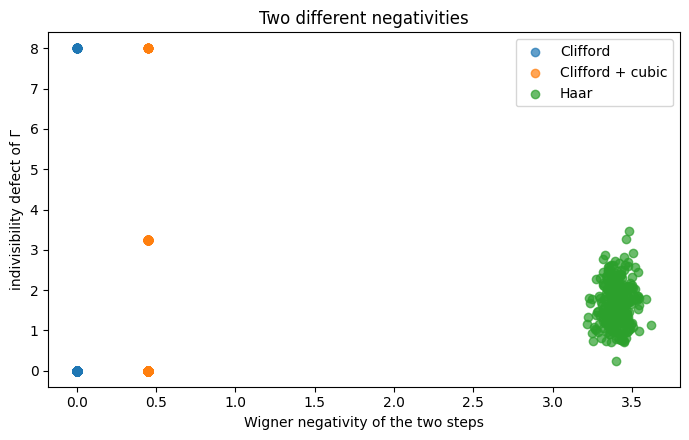

In [6]:
gens = [ps.fourier(), ps.shear(), ps.X, ps.Z]

def clifford_word(n):
    U = np.eye(d)
    for g in rng.integers(0, 4, n):
        U = gens[g] @ U
    return U

results = {}
for kind in ["Clifford", "Clifford + cubic", "Haar"]:
    D, N = [], []
    singular, neg_derived = 0, 0                        # the two forms of indivisibility
    for _ in range(300):
        if kind == "Clifford":
            U1, U2 = clifford_word(6), clifford_word(6)
        elif kind == "Clifford + cubic":
            U1, U2 = clifford_word(6), clifford_word(3) @ C @ clifford_word(3)
        else:
            U1, U2 = unitary_group.rvs(d, random_state=rng), unitary_group.rvs(d, random_state=rng)
        G1, G12 = np.abs(U1) ** 2, np.abs(U2 @ U1) ** 2
        D.append(indivisibility_defect(G1, G12))
        N.append(negative_mass(ps.wigner_map(U1)) + negative_mass(ps.wigner_map(U2)))
        if abs(np.linalg.det(G1)) < 1e-9:
            singular += D[-1] > 0
        else:
            neg_derived += (G12 @ np.linalg.inv(G1)).min() < -1e-9
    D, N = np.array(D), np.array(N)
    results[kind] = (D, N)
    if N.std() < 1e-9:                                  # a constant cannot be rank-correlated with anything
        corr = "n/a (no negativity)" if N.max() < 1e-9 else f"n/a (negativity constant, {N.mean():.3f})"
    else:
        r, pval = spearmanr(D, N)
        corr = f"{r:+.2f} (p = {pval:.2f})"
    print(f"{kind:17s}: indivisible {np.mean(D > 0):4.0%}   Wigner-negative {np.mean(N > 0):4.0%}"
          f"   mean defect {D.mean():.2f}   mean negativity {N.mean():.2f}   rank correlation {corr}")
    print(f"{'':17s}  indivisible pairs: {np.sum(D > 0)}, of which Γ(U1) singular: {singular}, "
          f"Γ(U1) invertible with a negative derived intermediate: {neg_derived}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for kind, (D, N) in results.items():
    ax.scatter(N, D, label=kind, alpha=0.7)
ax.set_xlabel('Wigner negativity of the two steps'); ax.set_ylabel('indivisibility defect of Γ')
ax.set_title('Two different negativities'); ax.legend()
plt.tight_layout(); plt.show()

### 📖 In depth: reading the scatter

- **Clifford (left edge, negativity 0).** About 90% of pairs are divisible. The rest sit at a defect of 8, the largest possible for 5 configurations: the all-or-nothing
  pattern of the Fourier example, where the first step spreads a configuration uniformly and the second gathers it back through the momentum.
- **Clifford + cubic (negativity 0.45).** Every pair is negative, by exactly the same amount, because the cubic gate contributes and the Clifford gates around it only permute
  phase space. So the points sit on one vertical line and a correlation cannot be measured. About 28% are indivisible, with defects of either about 3.2 or 8; whether a
  pair is indivisible is decided by the Clifford gates around the cubic one.
- **Haar.** Every sampled pair is both indivisible and negative, and the rank correlation is weak (+0.09, p = 0.14; five other 300-pair seeds gave between −0.10 and
  +0.14, with no consistent sign): knowing how negative the phase-space map is does not reliably predict how indivisible Γ is.
- **Which form.** The second printed line per ensemble shows that every indivisible Clifford and Clifford + cubic pair has a singular $\Gamma(U_1)$; only the Haar pairs,
  which are all Wigner-negative, show notebook 03's negative derived intermediate.

<!-- expansion:13:recap-5 -->
### 📝 Recap: section 5

- Random Clifford pairs: never negative; about 10% indivisible, all of those at the maximal defect.
- One cubic gate added: always negative, by the same amount, so no correlation can be measured; about 28% indivisible.
- Haar-random pairs: all 300 sampled pairs have both, with no consistent correlation in size.
- Without Wigner negativity, every indivisible pair had a singular $\Gamma(U_1)$; notebook 03's negative derived intermediate appeared only in the (Wigner-negative) Haar pairs.
- So indivisibility and Wigner negativity are different properties, in examples and in bulk, but the split is not symmetric.


### 🔭 Looking ahead

**Connections.**
- Notebook 12 found another way to trade indivisibility for a Markov chain: imaginary time. There the chain was on the same configurations; here it is on a bigger space with signs.
- Backlog item 4 (identical particles) and item 5 (Aharonov–Bohm) both involve phases that Γ forgets; the phase-space picture may make the "where did the information go"
  question concrete for them too.
- A continuous version: Schleich's harmonic oscillator, with Γ in position and time evolution as a phase-space rotation, is the continuum analogue of the Fourier example.

**Prior work (checked 2026-10-29).**
- $\Gamma = \Pi M E$ is known: it is how a quasi-probability simulation gives outcome probabilities (Pashayan, Wallman and Bartlett (2015), eq. 3, eq. 7 for circuits; Veitch et al. (2012);
  Mari and Eisert (2012)). The negative mass used in section 5 is their unitary negativity (eq. 6), via $M_U = 1 + 2\times$ negative mass. Veitch et al. (2012) and Mari and Eisert (2012) also tie Wigner negativity to the cost of classical simulation.
- That the two negativities come apart is known in substance: Clifford dynamics is a non-negative phase-space permutation in that work. Here it is restated in Γ language.
- That indivisibility comes from forgetting a coordinate whose inclusion makes the dynamics Markov is close to Barandes's own picture (Paper 3, §2.1, makes the
  Newtonian version: positions alone are second-order non-Markovian, while positions and velocities at the present time suffice;
  Barandes, "A Deflationary Account of Quantum Theory and its Implications for the Complex Numbers", arXiv:2602.01043, §3 and §5–6: the
  Hilbert-space formalism as a "Markovian embedding"). The Wigner map is one concrete, signed such embedding.
- Wootters's discrete Wigner function (Wootters 1987, *Ann. Phys.* 176, 1) is defined for every $d$, composite $d$ included (on a product of prime-dimensional phase
  spaces), so the unfolding is not tied to odd $d$; only the Clifford-permutation property is.
- Open question: whether a negative derived intermediate (notebook 03's form) can ever occur without Wigner negativity. It cannot when the first step is a one-qudit
  Clifford gate in prime $d$ (see the Summary); the general case is not settled here.
- Background: Wootters (1987) and Gross (2006) for the discrete Wigner function; Spekkens (2007) for a classical toy theory that reproduces stabilizer behaviour.

**Question for later.** Is there a quasi-probability frame in which indivisibility is a resource monotone? Resource theories of non-Markovianity exist
(e.g. arXiv:1803.06881, arXiv:1907.07003); none tied to a quasi-probability frame was found in our searches.

## Summary

- **Γ has a phase-space unfolding.** The Wigner map $M(U)$ composes exactly and its columns sum to 1, so on phase space the dynamics always splits at any intermediate time, at the
  price of negative entries. Γ is its marginal, $\Gamma = \Pi M E$: the configurations, with the momentum forgotten. A division event is "forget the momentum and start it
  uniform again", $E\Pi$. The unfolding is not special to odd $d$: Wootters's discrete Wigner function (Wootters 1987, *Ann. Phys.* 176, 1) is defined for every $d$
  (for composite $d$, on a product of prime-dimensional phase spaces), with the same marginal property and with each configuration uniform on its line, so $\Gamma = \Pi M E$
  carries over (not computed here). Nor is it special to unitary Γ: every ISP is either unistochastic or a subsystem of a unistochastic process (the stochastic-quantum
  theorem: Paper 2; Paper 3, §3.5), whose Wigner map gives a signed unfolding after also forgetting the ancilla (not demonstrated here). Only "Clifford gates act as
  permutations" (section 3) needs odd $d$.
- **The two negativities come apart.**
  - The Fourier gate moves phase space by a pure permutation (classical, deterministic, no negativity), yet the two-step process $F\cdot F$ is indivisible: $\Gamma(F)$
    is uniform and $\Gamma(F^2)$ is a permutation, which no stochastic matrix can produce from a uniform one. Because $\Gamma(F)$ is singular, notebook 03's derived
    intermediate does not exist here: no stochastic intermediate exists at all.
  - The cubic phase gate needs negative phase-space weights, yet its Γ is the identity, trivially divisible.
- **Over random circuits** neither implies the other: Clifford circuits are never Wigner-negative but sometimes indivisible; adding one cubic gate makes every circuit
  negative, by the same amount, but leaves most of them divisible; in all 300 sampled Haar pairs both are present. Their sizes show no consistent correlation: the
  rank correlation is +0.09 (p = 0.14) here, and five other seeds of 300 pairs gave values between −0.10 and +0.14, with no consistent sign.
- **The split is not symmetric.** In every indivisible Clifford and Clifford + cubic pair, $\Gamma(U_1)$ was singular: the indivisibility had the Fourier form.
  Notebook 03's form, an invertible $\Gamma(U_1)$ whose derived intermediate has negative entries, appeared only in the Haar pairs, which are also Wigner-negative.
  When the first step is Clifford (one qudit, prime $d$) it cannot appear: such a Γ is either a permutation, and then the derived intermediate is just $\Gamma(U_2)$, or uniform,
  and then it does not exist (every Clifford word we sampled at $d = 5$ and $7$ gave one of the two). Whether a negative derived intermediate requires Wigner negativity in general is not settled here.
- **So indivisibility is not Wigner negativity.** Indivisibility can be the cost of forgetting a hidden coordinate that moves entirely classically. Schleich puts the
  quantum properties of quadratic dynamics "in the initial condition"; in ISP the initial condition is a configuration, whose Wigner function is non-negative, and the
  indivisibility comes from what Γ forgets.

Caveats: one odd dimension (plus a $d = 7$ check), one choice of discrete Wigner function, pairs of steps only.

Prior work: $\Gamma = \Pi M E$ is the standard way a quasi-probability simulation turns phase-space dynamics into outcome probabilities (Pashayan, Wallman and Bartlett
(2015), eq. 3, eq. 7 for circuits; Veitch et al. (2012); Mari and Eisert (2012)). The negative mass used in section 5 is their unitary negativity (eq. 6),
via $M_U = 1 + 2\times$ negative mass. That Clifford dynamics is a non-negative permutation of phase space, so that the two negativities come apart, is
known in substance from the same work. The ISP reading (indivisibility as forgetting the momentum) restates it in Γ language.
That indivisibility comes from forgetting a coordinate whose inclusion makes the dynamics Markov is close to Barandes's own picture (Paper 3, §2.1, makes the
Newtonian version: positions alone are second-order non-Markovian, while positions and velocities at the present time suffice;
Barandes, "A Deflationary Account of Quantum Theory and its Implications for the Complex Numbers", arXiv:2602.01043, §3 and §5–6: the
Hilbert-space formalism as a "Markovian embedding"). The Wigner map is one concrete, signed such embedding.

### 📖 In depth: the one-paragraph version

Γ is the configuration log of a process that, on phase space, composes exactly: the Wigner map $M$. Γ forgets the momentum, $\Gamma = \Pi M E$, and that forgetting is what makes it
indivisible. A Clifford gate shuffles phase space like a classical deterministic system and still gives an indivisible Γ, because the momentum carries the memory. A cubic phase
gate needs negative phase-space weights and still gives a trivial Γ, because it moves no configuration. Over random circuits neither implies the other, and for Haar-random
pairs there is no consistent correlation in size. The split is not symmetric: without Wigner negativity, the indivisibility seen here always has a singular first step (no
intermediate at all), never notebook 03's negative derived intermediate. Indivisibility and Wigner negativity are different things: one is about what is forgotten, the
other about what cannot be unfolded positively.

<!-- expansion:13:check -->
### 📝 Check your understanding

1. *Does an indivisible Γ prove the dynamics is non-classical?*
   No. The Fourier gate is a deterministic permutation of phase space, and the two-step process $F\cdot F$ is maximally indivisible (of the singular kind: $\Gamma(F)$
   cannot be inverted, so no stochastic intermediate exists at all).
2. *Where does the memory go in the Fourier example?*
   Into the momentum, which Γ forgets; the second step turns it back into configuration.
3. *What is a division event in phase space?*
   $E\Pi$: keep the configuration probabilities, reset the momentum to uniform.
4. *Can a process need negative phase-space weights and still have a trivial Γ?*
   Yes: the cubic phase gate, $\Gamma = I$.
5. *How does this sit with Schleich's "quantum properties hidden in the initial condition"?*
   ISP starts from configurations, whose Wigner functions are non-negative; under quadratic (Clifford) dynamics they stay non-negative, yet Γ is indivisible. The
   indivisibility comes from what Γ forgets, not from the initial condition.
